# The Flea Beetle Problem

This notebook is part of [Bite Size Bayes](https://allendowney.github.io/BiteSizeBayes/), an introduction to probability and Bayesian statistics using Python.

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/BiteSizeBayes/blob/master/solutions/flea_beetle_soln.ipynb)

The following cell downloads `utils.py`, which contains some utility function we'll need.

In [1]:
from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve
        local, _ = urlretrieve(url, filename)
        print('Downloaded ' + local)

download('https://github.com/AllenDowney/BiteSizeBayes/raw/master/utils.py')

If everything we need is installed, the following cell should run with no error messages.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Introduction

This notebook introduces Bayesian classification.  As an example, I use data from three species of flea beetle to classify a hypothetical new specimen.

This problem is based on [this data story on DASL](https://web.archive.org/web/20160304083805/http://lib.stat.cmu.edu/DASL/Datafiles/FleaBeetles.html), which is based on Lubischew, A.A. (1962), "On the use of discriminant functions in taxonomy". Biometrics, 18, 455-477.

> Different species of flea beetle can be distinguished by the width and angle of the aedeagus.  The data below includes measurements and known species classification for 74 specimens.
>
>Suppose you discover a new specimen under conditions where it is equally likely to be any of the three species.  You measure the aedeagus and find width 140 microns and angle 15 (in multiples of 7.5 degrees).  What is the probability that it belongs to each species?

### Data

Description: Data were collected on the genus of flea beetle Chaetocnema, which contains three species: concinna (Con), heikertingeri (Hei), and heptapotamica (Hep). Measurements were made on the width and angle of the aedeagus of each beetle. The goal of the original study was to form a classification rule to distinguish the three species.

Number of cases: 74

Variable Names:

Width: The maximal width of aedeagus in the forpart (in microns)

Angle: The front angle of the aedeagus (1 unit = 7.5 degrees)

Species: Species of flea beetle from the genus Chaetocnema

We can read the data from this file:

In [3]:
# Load the data file
import os

if not os.path.exists('flea_beetles.csv'):
    !wget https://github.com/AllenDowney/BiteSizeBayes/raw/master/flea_beetles.csv

--2021-03-29 10:31:06--  https://github.com/AllenDowney/BiteSizeBayes/raw/master/flea_beetles.csv
Resolving github.com (github.com)... 140.82.113.3
Connecting to github.com (github.com)|140.82.113.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/AllenDowney/BiteSizeBayes/master/flea_beetles.csv [following]
--2021-03-29 10:31:07--  https://raw.githubusercontent.com/AllenDowney/BiteSizeBayes/master/flea_beetles.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 828 [text/plain]
Saving to: ‘flea_beetles.csv’

flea_beetles.csv    100%[===================>]     828  --.-KB/s    in 0s      

2021-03-29 10:31:07 (44.2 MB/s) - ‘flea_beetles.csv’ saved [828/828]



In [4]:
df = pd.read_csv('flea_beetles.csv', delimiter='\t')
df.head()

,Width,Angle,Species
0,150,15,Con
1,147,13,Con
2,144,14,Con
3,144,16,Con
4,153,13,Con


Here's what the distributions of width look like.

In [5]:
def plot_cdfs(df, col):
    for name, group in df.groupby('Species'):
        cdf = Cdf(group[col], label=name)
        thinkplot.Cdf(cdf)
    
    thinkplot.decorate(xlabel=col, 
                       ylabel='CDF',
                       loc='lower right')

In [6]:
from scipy.stats import gaussian_kde

def plot_kdes(df, col):
    xs = np.linspace(df[col].min(), df[col].max())
    
    for name, group in df.groupby('Species'):
        kde = gaussian_kde(group[col])
        ys = kde.evaluate(xs)
        plt.plot(xs, ys, label=name)
        
    plt.xlabel('Measurement')
    plt.ylabel('Probability density')
    plt.legend()

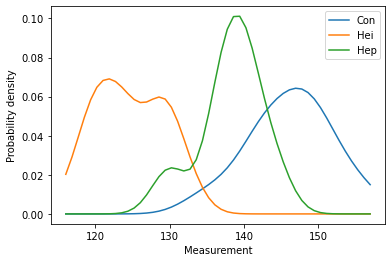

In [7]:
plot_kdes(df, 'Width')

And the distributions of angle.

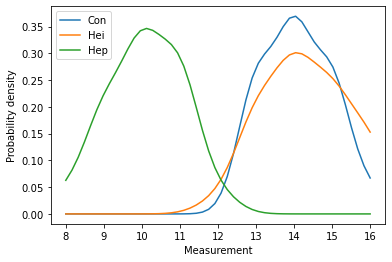

In [8]:
plot_kdes(df, 'Angle')

I'll group the data by species and compute summary statistics.

In [9]:
grouped = df.groupby('Species')

Here are the means.

In [10]:
means = grouped.mean()
means

,Width,Angle
Species,,
Con,146.190476,14.095238
Hei,124.645161,14.290323
Hep,138.272727,10.090909


And the standard deviations.

In [11]:
stddevs = grouped.std()
stddevs

,Width,Angle
Species,,
Con,5.626891,0.889087
Hei,4.622758,1.101319
Hep,4.142484,0.971454


And the correlations.

In [12]:
for name, group in grouped:
    corr = group.Width.corr(group.Angle)
    print(name, corr)

Con -0.193701151757636
Hei -0.06420611481268004
Hep -0.12478515405529579


Those correlations are small enough that we can get an acceptable approximation by ignoring them, but we might want to come back later and write a complete solution that takes them into account.

## Computing likelihoods

In [13]:
from scipy.stats import norm

dist_width = {}
dist_angle = {}
for name, group in grouped:
    dist_width[name] = norm(group.Width.mean(), group.Width.std())
    dist_angle[name] = norm(group.Angle.mean(), group.Angle.std())

In [14]:
table = pd.DataFrame()
table['hypo'] = ['Con', 'Hei', 'Hep']
table['prior'] = 1/3
table

,hypo,prior
0,Con,0.333333
1,Hei,0.333333
2,Hep,0.333333


In [15]:
table['likelihood'] = [dist_width[hypo].pdf(140) 
                       for hypo in table['hypo']]
table

,hypo,prior,likelihood
0,Con,0.333333,0.038709
1,Hei,0.333333,0.000347
2,Hep,0.333333,0.088287


We'll start with equal priors

In [16]:
table['unnorm'] = table['prior'] * table['likelihood']
prob_data = table['unnorm'].sum()
table['posterior'] = table['unnorm'] / prob_data
table

,hypo,prior,likelihood,unnorm,posterior
0,Con,0.333333,0.038709,0.012903,0.303977
1,Hei,0.333333,0.000347,0.000116,0.002724
2,Hep,0.333333,0.088287,0.029429,0.693298


In [17]:
table2 = pd.DataFrame()
table2['hypo'] = table['hypo']
table2['prior'] = table['posterior']

In [18]:
table2['likelihood'] = [dist_angle[hypo].pdf(15) 
                       for hypo in table['hypo']]
table2

,hypo,prior,likelihood
0,Con,0.303977,0.267359
1,Hei,0.002724,0.294327
2,Hep,0.693298,0.000001


In [19]:
table2['unnorm'] = table2['prior'] * table2['likelihood']
prob_data = table2['unnorm'].sum()
table2['posterior'] = table2['unnorm'] / prob_data
table2

,hypo,prior,likelihood,unnorm,posterior
0,Con,0.303977,0.267359,8.127101e-02,0.99022
1,Hei,0.002724,0.294327,8.018754e-04,0.00977
2,Hep,0.693298,0.000001,8.114748e-07,0.00001


Based on these measurements, the specimen is very likely to be an example of *Chaetocnema concinna*.

Copyright 2020–2026 Allen Downey

Code license: [MIT License](https://opensource.org/license/MIT)

Text license: [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/)